In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statistics
import Funcs as fn
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, SimpleImputer, IterativeImputer

#Data Balancing
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_excel('CleanedFile.xlsx')

In [4]:
df

,Demo key,DOB,IndexDate,Age,# Cells Counted,Abs Band,Abs Basophil,Abs Blast,Abs Eosinophil,Abs Lymphocytes,...,Survived\n1 Year,Survived\n5 Years,KPS,GVHD Prophylaxis,Preparative Regimen,Complication,Complication Status,Comorbidity Index,Transplant Date,Vital Status_Code
0,AU001,1958-09-08,2019-01-22,60.0,100.0,NaN,NaN,NaN,NaN,3.5,...,UNKNOWN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-29,0.0
1,AU003,1944-07-25,2019-01-02,74.0,100.0,0.3,0.2,NaN,NaN,1.0,...,TRUE,FALSE,NaN,NaN,NaN,Metabolic/Laboratory-Creatinine,Grade 3,NaN,2019-01-14,1.0
2,AU004,2004-07-17,2019-01-03,14.0,200.0,1.9,NaN,NaN,NaN,4.5,...,TRUE,FALSE,NaN,NaN,NaN,Gastrointestinal-Mucositis/Stomatitis,Grade 3,NaN,2019-04-02,1.0
3,AU005,1958-03-26,2019-01-08,60.0,100.0,2.3,0.9,NaN,NaN,5.0,...,UNKNOWN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-15,0.0
4,AU006,1960-05-05,2019-01-09,58.0,100.0,NaN,0.2,NaN,0.2,3.5,...,UNKNOWN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-15,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1188,AU995,1959-06-08,2023-11-14,64.0,100.0,2.0,NaN,NaN,0.7,2.7,...,UNKNOWN,NaN,90.0,NaN,Adult Melphalan 140 mg/m2,NaN,NaN,4.0,2023-11-22,0.0
1189,AU996,1977-08-02,2023-11-14,46.0,200.0,NaN,0.5,NaN,1.6,2.6,...,UNKNOWN,NaN,90.0,NaN,Adult Melphalan 200 mg/m2,NaN,NaN,4.0,2023-11-21,0.0
1190,AU997,1981-12-13,2023-11-15,41.0,100.0,2.0,NaN,NaN,NaN,5.5,...,UNKNOWN,NaN,60.0,NaN,Adult Melphalan 200 mg/m2,NaN,NaN,2.0,2023-11-22,0.0
1191,AU998,1961-07-28,2023-11-20,62.0,NaN,0.4,NaN,NaN,0.4,3.6,...,TRUE,NaN,90.0,NaN,Adult Melphalan 200 mg/m2,NaN,NaN,NaN,2023-11-29,0.0


# Imputation

In [21]:
# MICE Style Approach

# use fn to remove numerical values, and columns with >70% NaN
numdf = fn.structure_missing_values_numeric(df)

# get numeric columns
num_col = numdf.columns

# Create Iterative Imputer
imp = IterativeImputer(max_iter=20, random_state=0)

# Impute missing numeric values
numdf[num_col] = imp.fit_transform(numdf[num_col])

#use fn to remove categorical values, and columns with >70% NaN
catdf = fn.structure_missing_values_categorical(df)

# get cat. columns
cat_col = catdf.select_dtypes(include="object").columns

# Create Simple Imputer
imp = SimpleImputer(strategy='most_frequent')

# Impute missing categorical values
catdf[cat_col] = imp.fit_transform(catdf[cat_col])

# COMBINE NUMERIC + CATEGORICAL
df_imputed = pd.concat([numdf, catdf], axis=1)

# Save
df_imputed.to_csv("ImputedData.csv", index=False)

display(df_imputed)


,Age,# Cells Counted,Abs Band,Abs Eosinophil,Abs Lymphocytes,Abs Metamyelocyte,Abs Monocyte,Abs Myelocyte,Abs Neutrophil,Anion Gap,...,Mobilization type (Excluding 0's,Mobilzation type (5.0),PB Cutoff,Vital Status,Most Recent Encounter,Survived\n30 Days,Survived\n100 Days,Survived\n1 Year,Preparative Regimen,Transplant Date
0,60.0,100.000000,-1.985785,0.384554,3.5,-0.303566,0.148289,-0.957537,31.2,11.0,...,Good,Good,Poor,Alive,2019-02-15,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-29
1,74.0,100.000000,0.300000,0.097409,1.0,-0.593493,0.800000,0.200000,14.2,9.0,...,Poor,Poor,Poor,Dead,2021-05-23,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-14
2,14.0,200.000000,1.900000,0.953757,4.5,1.222263,0.600000,0.625977,57.0,8.0,...,Poor,Poor,Poor,Dead,2021-07-06,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-04-02
3,60.0,100.000000,2.300000,1.094691,5.0,0.528866,1.800000,0.500000,35.3,8.0,...,Poor,Poor,Poor,Alive,2019-02-01,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-15
4,58.0,100.000000,-0.842537,0.200000,3.5,0.800000,3.000000,0.200000,8.2,11.0,...,Good,Good,Good,Alive,2019-01-30,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1188,64.0,100.000000,2.000000,0.700000,2.7,1.107368,4.100000,1.153456,58.3,12.0,...,Good,Good,Poor,Alive,2023-11-21,TRUE,TRUE,TRUE,Adult Melphalan 140 mg/m2,2023-11-22
1189,46.0,200.000000,0.842853,1.600000,2.6,0.500000,4.200000,0.926228,43.3,11.0,...,Good,Good,Good,Alive,2023-11-20,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-21
1190,41.0,100.000000,2.000000,0.145307,5.5,1.000000,8.500000,0.500000,32.4,7.0,...,Good,Good,Good,Alive,2024-02-05,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-22
1191,62.0,114.674384,0.400000,0.400000,3.6,0.900000,7.700000,0.761609,32.2,12.0,...,Good,Good,Good,Alive,2025-01-09,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-29


In [7]:
# KNN Approach

# Get usable numeric data
numdf = fn.structure_missing_values_numeric(df)

# Get numeric columns
num_col = numdf.columns

# Create KNN Imputer
knn_imp = KNNImputer(n_neighbors=5)

# Impute missing numeric values
numdf[num_col] = knn_imp.fit_transform(numdf[num_col])

# Get usable categorical data
catdf = fn.structure_missing_values_categorical(df)

# Get categorical columns
cat_col = catdf.select_dtypes(include="object").columns

# Create categorical imputer
cat_imp = SimpleImputer(strategy="most_frequent")

# Impute missing categorical values
catdf[cat_col] = cat_imp.fit_transform(catdf[cat_col])

# combine both df
df_knn = pd.concat([numdf, catdf], axis=1)

# Save
df_knn.to_csv("KNN_ImputedData.csv", index=False)

display(df_knn)

,Age,# Cells Counted,Abs Band,Abs Eosinophil,Abs Lymphocytes,Abs Metamyelocyte,Abs Monocyte,Abs Myelocyte,Abs Neutrophil,Anion Gap,...,Mobilization type (Excluding 0's,Mobilzation type (5.0),PB Cutoff,Vital Status,Most Recent Encounter,Survived\n30 Days,Survived\n100 Days,Survived\n1 Year,Preparative Regimen,Transplant Date
0,60.0,100.0,3.40,0.76,3.5,1.16,2.64,0.96,31.2,11.0,...,Good,Good,Poor,Alive,2019-02-15,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-29
1,74.0,100.0,0.30,1.26,1.0,0.96,0.80,0.20,14.2,9.0,...,Poor,Poor,Poor,Dead,2021-05-23,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-14
2,14.0,200.0,1.90,1.72,4.5,1.72,0.60,1.20,57.0,8.0,...,Poor,Poor,Poor,Dead,2021-07-06,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-04-02
3,60.0,100.0,2.30,1.48,5.0,0.56,1.80,0.50,35.3,8.0,...,Poor,Poor,Poor,Alive,2019-02-01,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-15
4,58.0,100.0,1.18,0.20,3.5,0.80,3.00,0.20,8.2,11.0,...,Good,Good,Good,Alive,2019-01-30,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2019-01-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1188,64.0,100.0,2.00,0.70,2.7,0.58,4.10,0.96,58.3,12.0,...,Good,Good,Poor,Alive,2023-11-21,TRUE,TRUE,TRUE,Adult Melphalan 140 mg/m2,2023-11-22
1189,46.0,200.0,2.00,1.60,2.6,0.50,4.20,1.06,43.3,11.0,...,Good,Good,Good,Alive,2023-11-20,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-21
1190,41.0,100.0,2.00,1.18,5.5,1.00,8.50,0.50,32.4,7.0,...,Good,Good,Good,Alive,2024-02-05,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-22
1191,62.0,120.0,0.40,0.40,3.6,0.90,7.70,0.48,32.2,12.0,...,Good,Good,Good,Alive,2025-01-09,TRUE,TRUE,TRUE,Adult Melphalan 200 mg/m2,2023-11-29


In [11]:
df_mice = pd.read_csv("ImputedData.csv")

df_knn = pd.read_csv("KNN_ImputedData.csv")

In [8]:
df.columns.tolist()

['Demo key',
 'DOB',
 'IndexDate',
 'Age',
 '# Cells Counted',
 'Abs Band',
 'Abs Basophil',
 'Abs Blast',
 'Abs Eosinophil',
 'Abs Lymphocytes',
 'Abs Metamyelocyte',
 'Abs Monocyte',
 'Abs Myelocyte',
 'Abs Neutrophil',
 'Abs Other Cells Bld',
 'Abs Plasma Cell',
 'Abs Promyelocyte',
 'Albumin SerPl QN',
 'Alkaline Phos SerPl QN',
 'ALT SerPl QN',
 'Anion Gap',
 'aPTT',
 'AST SerPl QN',
 'Band',
 'Baso#',
 'Basophil',
 'Basophils %',
 'Bilirubin Total SerPl QN',
 'Blast',
 'BUN SerPl QN',
 'Calcium Total SerPl QN',
 'Chloride SerPl QN',
 'CO2 SerPl QN',
 'Creatinine SerPl QN',
 'Eos#',
 'Eosinophil',
 'Eosinophils %',
 'Estimated CRCL (CG)',
 'Estimated GFR (CKD-EPI, no race)',
 'Estimated GFR (CKD-EPI)',
 'Free Kappa L.C. Ser QN',
 'Free Kappa/Lambda Ratio',
 'Hct',
 'Hgb',
 'IgA Ser QN',
 'IgG Ser QN',
 'IgM Ser QN',
 'INR',
 'Lab Glucose',
 'LD SerPl QN',
 'Lym#',
 'Lymphocyte',
 'Lymphocytes %',
 'Magnesium SerPl QN',
 'MCH',
 'MCHC',
 'MCV',
 'Metamyelo',
 'Mono#',
 'Monocyte',


# Graphs

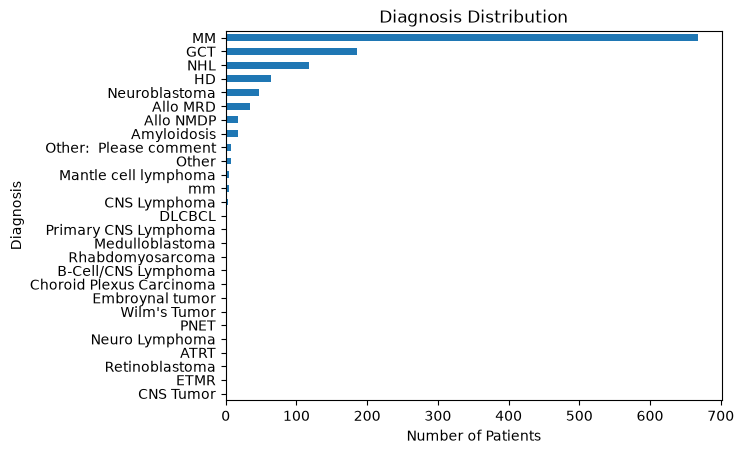

In [12]:
# 1. Graph a diagnosis distribution MICE

# select a column
diagnosis = df_mice["Diagnosis"]

# count each diagnosis
diagnosis_counts = diagnosis.value_counts()

# make the graph
ax = diagnosis_counts.plot(kind="barh")

# put most common diagnosis on the top
ax.invert_yaxis()

# Customize
plt.xlabel("Number of Patients")
plt.ylabel("Diagnosis")
plt.title("Diagnosis Distribution")

#save
plt.savefig("Diagnosis Distribution_MICE.png", bbox_inches="tight")

# show
plt.show()


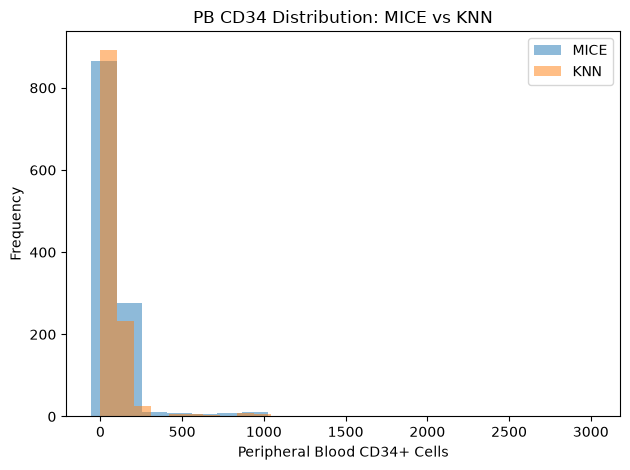

In [ ]:
# Compare PD CD34 distributions between KNN and MICE

column = "Peripheral Blood CD34+ Cells"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5, # makes semi transparent for overlap visualization
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5, 
    label="KNN"
)

plt.xlabel("Peripheral Blood CD34+ Cells")
plt.ylabel("Frequency")
plt.title("PB CD34 Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()
plt.show()

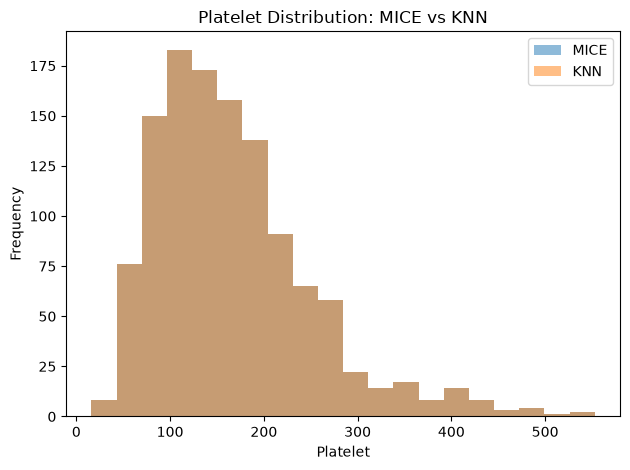

In [ ]:
# Compare platelet dist. between knn and mice

column = "Platelet"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Platelet Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Platelet Distribution.png", bbox_inches="tight")

plt.show()

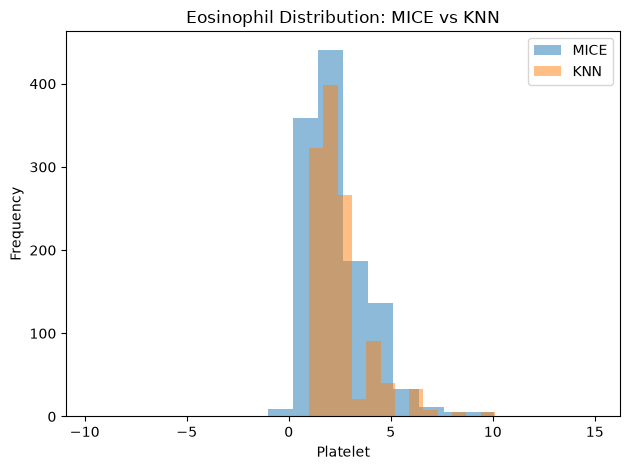

In [ ]:
# Compare Hgb dist. between knn and mice

column = "Eosinophil"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Eosinophil Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Eosinophil Dist.png", bbox_inches="tight")

plt.show()

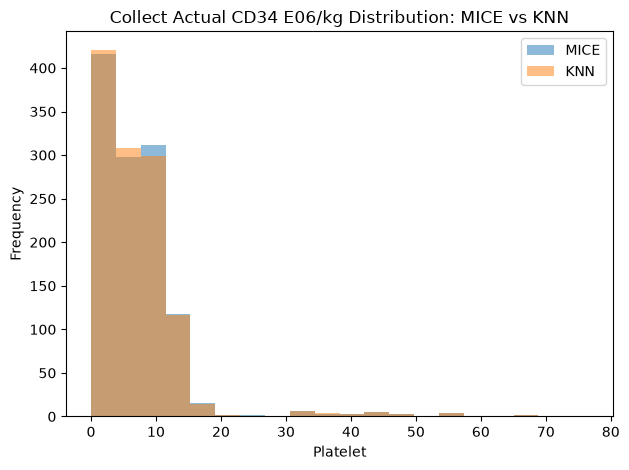

In [ ]:
# Compare collected cd34/kg dist. between knn and mice

column = "Collect Actual CD34 E06/kg"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Collect Actual CD34 E06/kg Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("cd34 dist.png", bbox_inches="tight")

plt.show()

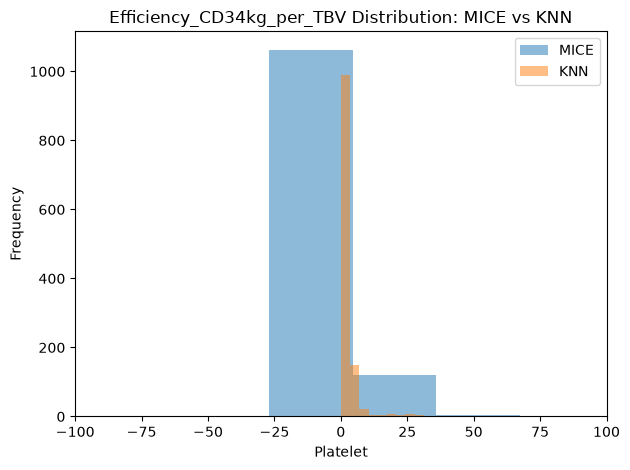

In [ ]:
# compare efficiency to knn vs mice

column = "Efficiency_CD34kg_per_TBV"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")

plt.xlim(-100, 100)
plt.title("Efficiency_CD34kg_per_TBV Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("efficiency dist.png", bbox_inches="tight")

plt.show()

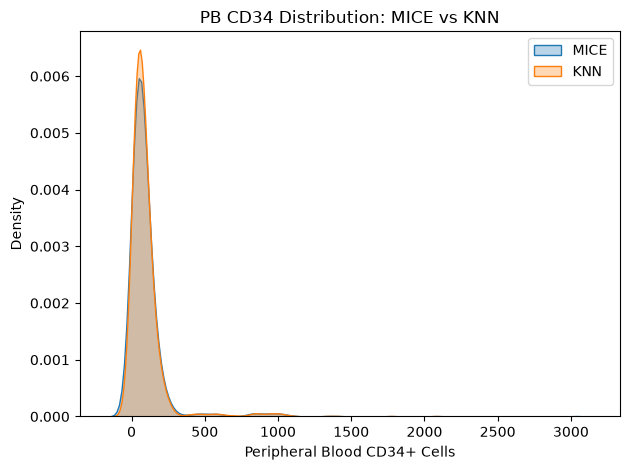

In [ ]:
# making a kde chart

column = "Peripheral Blood CD34+ Cells"

# KDE for MICE
sns.kdeplot(
    data=df_mice,
    x=column,
    label="MICE",
    fill=True,
    alpha=0.3
)

# KDE for KNN
sns.kdeplot(
    data=df_knn,
    x=column,
    label="KNN",
    fill=True,
    alpha=0.3
)

# Customize
plt.xlabel("Peripheral Blood CD34+ Cells")
plt.ylabel("Density")
plt.title("PB CD34 Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

# Save
plt.savefig(
    "PB_CD34_KDE_MICE_vs_KNN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

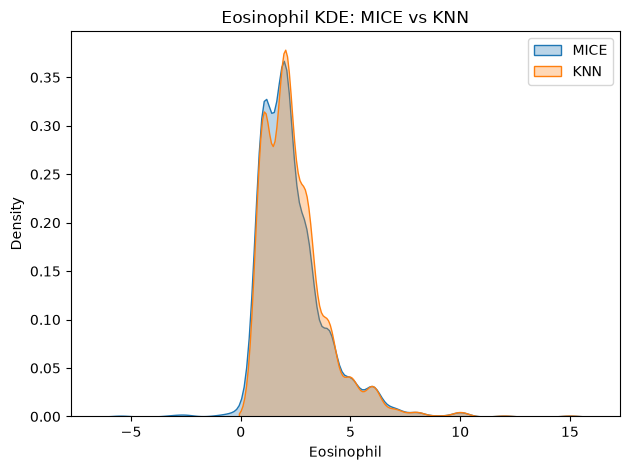

In [ ]:
# making a kde chart

column = "Eosinophil"

# KDE for MICE
sns.kdeplot(
    data=df_mice,
    x=column,
    label="MICE",
    fill=True,
    alpha=0.3
)

# KDE for KNN
sns.kdeplot(
    data=df_knn,
    x=column,
    label="KNN",
    fill=True,
    alpha=0.3
)

# Customize
plt.xlabel("Eosinophil")
plt.ylabel("Density")
plt.title("Eosinophil KDE: MICE vs KNN")
plt.legend()
plt.tight_layout()

# Save
plt.savefig(
    "eosinophil kde.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

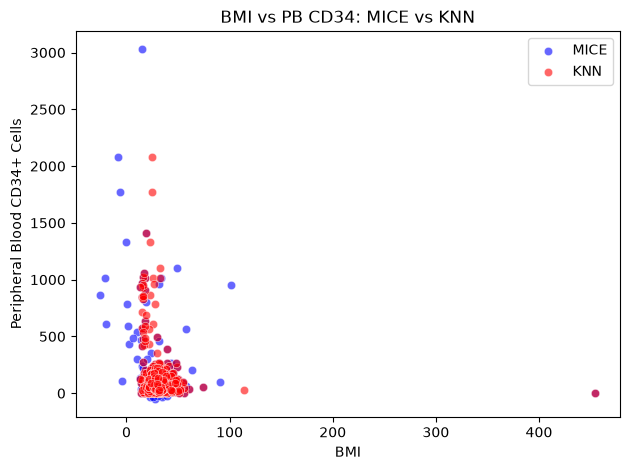

In [ ]:
# make a scatterplot

x = "BMI"
y = "Peripheral Blood CD34+ Cells"

# MICE
sns.scatterplot(
    data=df_mice,
    x=x,
    y=y,
    label="MICE",
    color="blue",
    alpha=0.6
)

# KNN
sns.scatterplot(
    data=df_knn,
    x=x,
    y=y,
    label="KNN",
    color="red",
    alpha=0.6
)

plt.xlabel("BMI")
plt.ylabel("Peripheral Blood CD34+ Cells")
plt.title("BMI vs PB CD34: MICE vs KNN")

plt.legend()
plt.tight_layout()
plt.savefig("BMI vs PB CD34.png")
plt.show()

In [ ]:
dfnum = df.select_dtypes(include='number')

dfcat = df.select_dtypes(include='object')

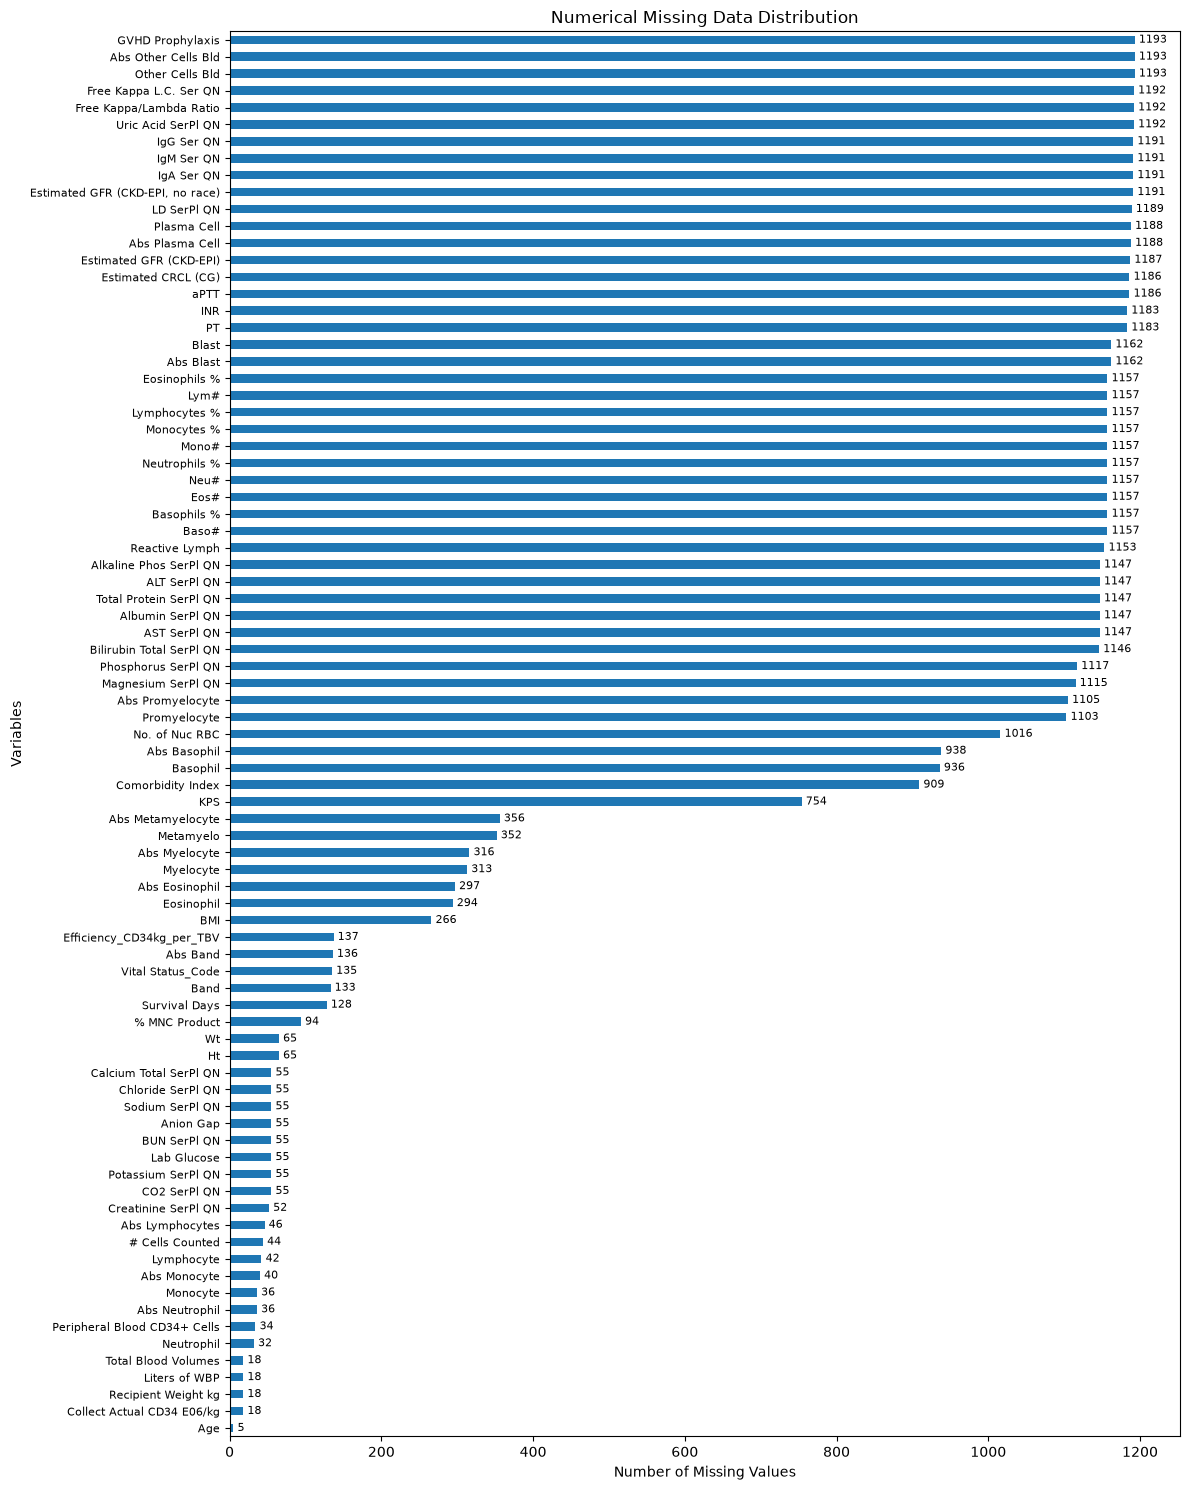

In [87]:

NaN_co = dfnum.isna().sum()[(dfnum.isna().sum() > 1) & (dfnum.isna().sum() <= 1193)]

NaN_col = NaN_co.sort_values(ascending=True)

# Make the graph taller
ax = NaN_col.plot(kind="barh", figsize=(12, 15))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Numerical Missing Data Distribution")

# Fix spacing
plt.tight_layout()

# Save
plt.savefig("NaN Num Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

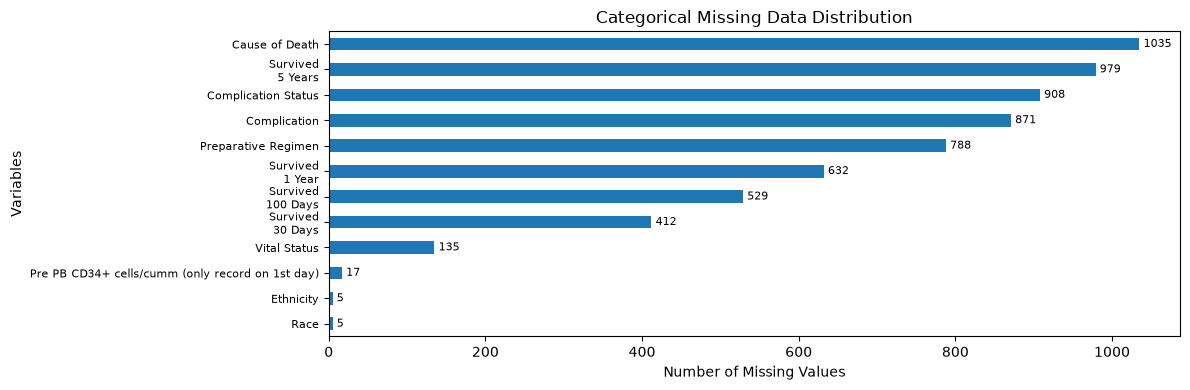

In [86]:

NaN_co2 = dfcat.isna().sum()[(dfcat.isna().sum() > 1) & (dfcat.isna().sum() <= 1193)]

NaN_col2 = NaN_co2.sort_values(ascending=True)

# Make the graph taller
ax = NaN_col2.plot(kind="barh", figsize=(12, 4))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Categorical Missing Data Distribution")

# Fix spacing
plt.tight_layout()

# Save
plt.savefig("NaN cat Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# graph BMI and abs eosinophil, diff between abs e. and e., 

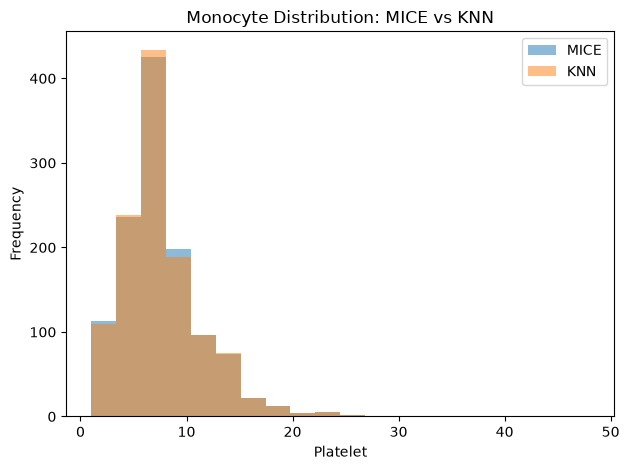

In [ ]:
column = "Monocyte"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Monocyte Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Monocyte Histogram.png", bbox_inches="tight")

plt.show()

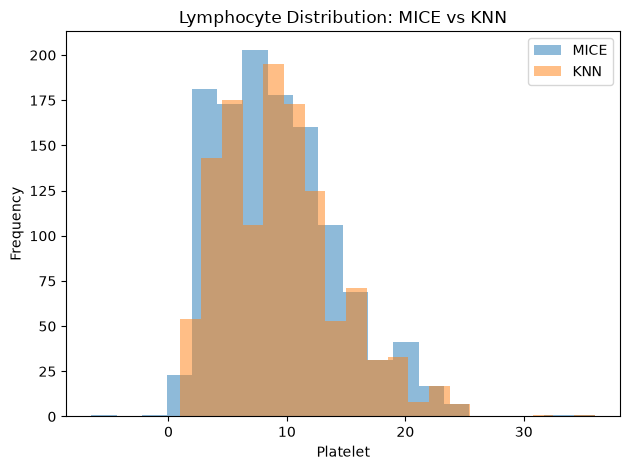

In [ ]:
column = "Lymphocyte"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Lymphocyte Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Lymphocyte Histogram.png", bbox_inches="tight")

plt.show()

In [ ]:
df["Lymphocyte"].isna().sum()

np.int64(42)

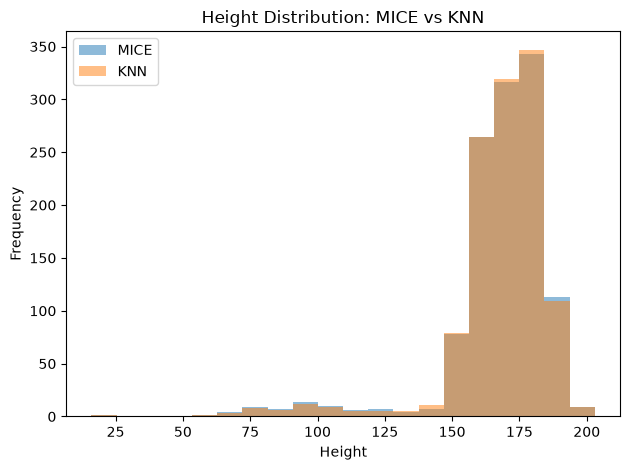

In [ ]:
column = "Ht"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Height")
plt.ylabel("Frequency")
plt.title("Height Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Ht Histogram.png", bbox_inches="tight")

plt.show()

In [ ]:
df["BMI"].isna().sum()

np.int64(266)

# Data Processing